In [6]:
import sys
print(sys.executable)
print(sys.version)


c:\Users\dhars\AppData\Local\Programs\Python\Python312\python.exe
3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]


In [7]:
%pip install pandas numpy matplotlib seaborn scikit-learn ipykernel

  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/10.8 MB ? eta -:--:--
   --- ------------------------------------ 1.0/10.8 MB 5.6 MB/s eta 0:00:02
   ----------- ---------------------------- 3.1/10.8 MB 8.4 MB/s eta 0:00:01
   ------------------- -------------------- 5.2/10.8 MB 9.1 MB/s eta 0:00:01
   ---------------------------- ----------- 7.6/10.8 MB 9.6 MB/s eta 0:00:01
   ------------------------------------- -- 10.0/10.8 MB 10.0 MB/s eta 0:00:01
   ---------------------------------------- 10.8/10.8 MB 9.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ------- -------------------------------- 2.4/12.6 MB 11.2 MB/s eta 0:00:01
   --------------- ------------------------ 5.0/12.6 MB 1

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [10]:
df = pd.read_csv("Dataset.csv")
print("Dataset loaded successfully!")
print("Shape:", df.shape)   
df.head()

Dataset loaded successfully!
Shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [11]:
print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
df.describe(include="all")

Column Names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8790 non-null   str  
 1   type          8790 non-null   str  
 2   title         8790 non-null   str  
 3   director      8790 non-null   str  
 4   country       8790 non-null   str  
 5   date_added    8790 non-null   str  
 6   release_year  8790 non-null   int64
 7   rating        8790 non-null   str  
 8   duration      8790 non-null   str  
 9   listed_in     8790 non-null   str  
dtypes: int64(1), str(9)
memory usage: 686.8 KB

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64



,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790.000000,8790,8790,8790
unique,8790,2,8787,4528,86,1713,NaN,14,220,513
top,s1,Movie,9-Feb,Not Given,United States,1/1/2020,NaN,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,NaN,3205,1791,362
mean,NaN,NaN,NaN,NaN,NaN,NaN,2014.183163,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,8.825466,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN


type
Movie      6126
TV Show    2664
Name: count, dtype: int64


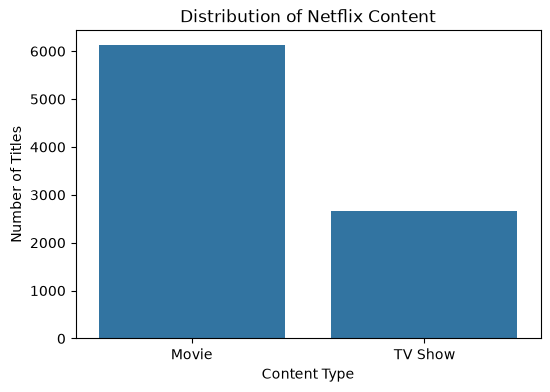

In [12]:
print(df['type'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='type')
plt.title('Distribution of Netflix Content')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()

Top 10 Netflix Genres:
listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


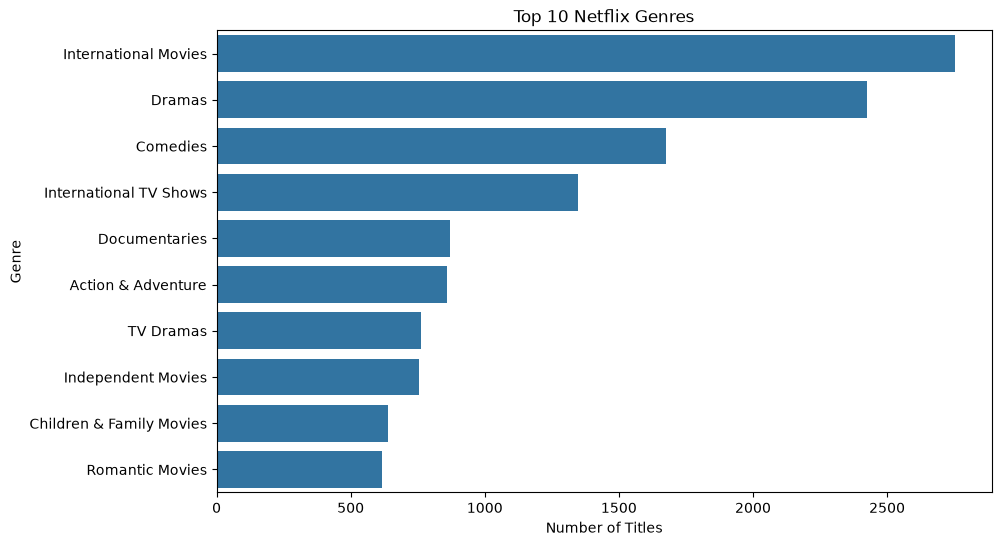

In [13]:
genres = df['listed_in'].str.split(', ').explode()

top_genres = genres.value_counts().head(10)

print("Top 10 Netflix Genres:")
print(top_genres)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)

plt.title('Top 10 Netflix Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')

plt.show()

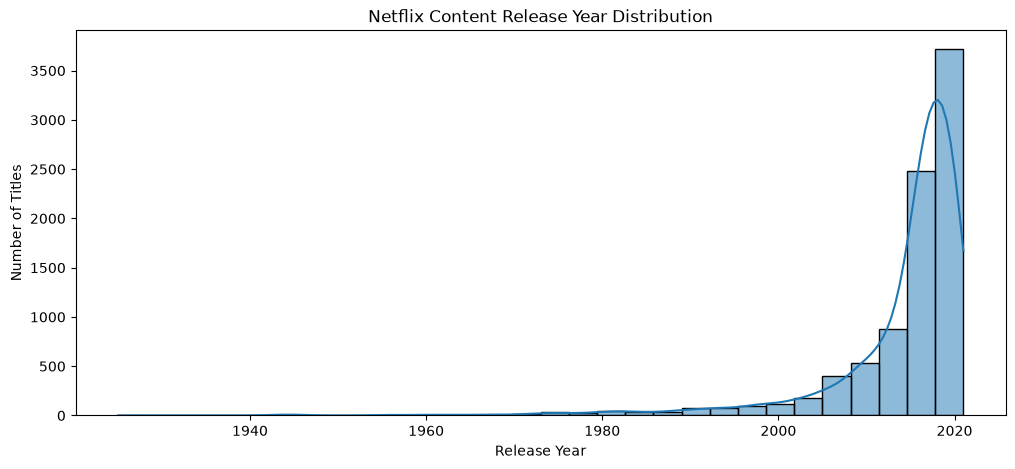

In [14]:
plt.figure(figsize=(12, 5))

sns.histplot(data=df, x='release_year', bins=30, kde=True)

plt.title('Netflix Content Release Year Distribution')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')

plt.show()

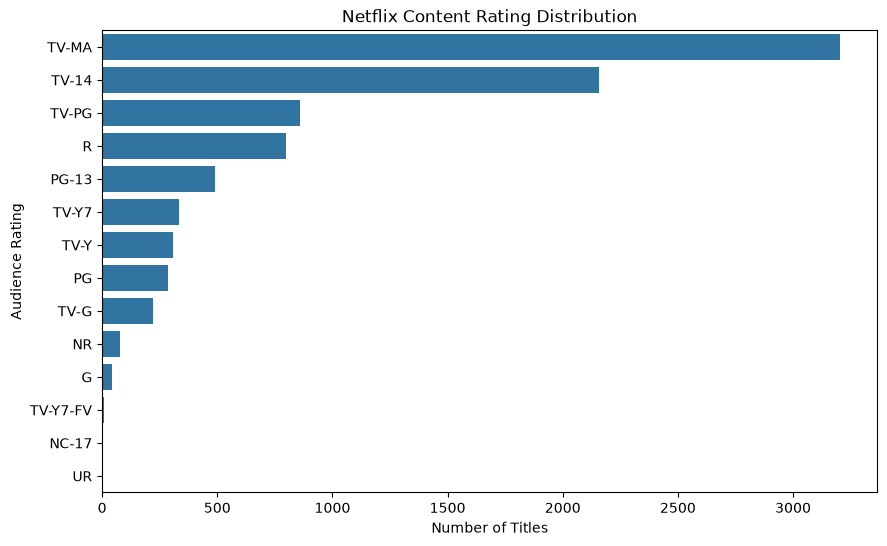

In [15]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y='rating',
    order=df['rating'].value_counts().index
)

plt.title('Netflix Content Rating Distribution')
plt.xlabel('Number of Titles')
plt.ylabel('Audience Rating')

plt.show()

In [16]:
features = [
    'type',
    'country',
    'release_year',
    'rating',
    'duration',
    'listed_in'
]

data = df[features].copy()

print("Selected Features:")
print(data.head())

print("\nDataset Shape:", data.shape)

Selected Features:
      type        country  release_year rating  duration  \
0    Movie  United States          2020  PG-13    90 min   
1  TV Show         France          2021  TV-MA  1 Season   
2  TV Show  United States          2021  TV-MA  1 Season   
3    Movie         Brazil          2021  TV-PG    91 min   
4    Movie  United States          1993  TV-MA   125 min   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dramas, TV Horror, TV Mysteries  
3                 Children & Family Movies, Comedies  
4   Dramas, Independent Movies, International Movies  

Dataset Shape: (8790, 6)


In [17]:
print("Unique Values in Each Feature:\n")

for col in features:
    print(f"{col}: {data[col].nunique()} unique values")

Unique Values in Each Feature:

type: 2 unique values
country: 86 unique values
release_year: 74 unique values
rating: 14 unique values
duration: 220 unique values
listed_in: 513 unique values


In [18]:
print("Sample Duration Values:")
print(data['duration'].value_counts().head(20))

print("\nContent Type vs Duration:")
print(data.groupby('type')['duration'].head(10))

Sample Duration Values:
duration
1 Season     1791
2 Seasons     421
3 Seasons     198
90 min        152
97 min        146
94 min        146
93 min        146
91 min        144
95 min        137
96 min        130
92 min        129
102 min       122
98 min        120
99 min        118
88 min        116
101 min       116
103 min       114
106 min       111
100 min       108
89 min        106
Name: count, dtype: int64

Content Type vs Duration:
0        90 min
1      1 Season
2      1 Season
3        91 min
4       125 min
5     9 Seasons
6       104 min
7        87 min
8       127 min
9        76 min
10       76 min
11       71 min
12      131 min
17     1 Season
18     1 Season
20     1 Season
21     1 Season
22     1 Season
24     1 Season
27     1 Season
Name: duration, dtype: str


In [19]:
# Extract movie duration in minutes
data['movie_duration'] = data['duration'].str.extract(r'(\d+) min').astype(float)

# Extract number of seasons
data['num_seasons'] = data['duration'].str.extract(r'(\d+) Season').astype(float)

# Replace missing values with 0
data['movie_duration'] = data['movie_duration'].fillna(0)
data['num_seasons'] = data['num_seasons'].fillna(0)

# Display the result
print(data[['type', 'duration', 'movie_duration', 'num_seasons']].head(15))

       type   duration  movie_duration  num_seasons
0     Movie     90 min            90.0          0.0
1   TV Show   1 Season             0.0          1.0
2   TV Show   1 Season             0.0          1.0
3     Movie     91 min            91.0          0.0
4     Movie    125 min           125.0          0.0
5   TV Show  9 Seasons             0.0          9.0
6     Movie    104 min           104.0          0.0
7     Movie     87 min            87.0          0.0
8     Movie    127 min           127.0          0.0
9     Movie     76 min            76.0          0.0
10    Movie     76 min            76.0          0.0
11    Movie     71 min            71.0          0.0
12    Movie    131 min           131.0          0.0
13    Movie     39 min            39.0          0.0
14    Movie     36 min            36.0          0.0


In [20]:
print("Movie Duration Statistics:")
print(data.loc[data['type'] == 'Movie', 'movie_duration'].describe())

print("\nTV Show Season Statistics:")
print(data.loc[data['type'] == 'TV Show', 'num_seasons'].describe())

print("\nMissing Values:")
print(data[['movie_duration', 'num_seasons']].isnull().sum())

Movie Duration Statistics:
count    6126.000000
mean       99.584884
std        28.283225
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: movie_duration, dtype: float64

TV Show Season Statistics:
count    2664.000000
mean        1.751877
std         1.550622
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: num_seasons, dtype: float64

Missing Values:
movie_duration    0
num_seasons       0
dtype: int64


Top 10 Countries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


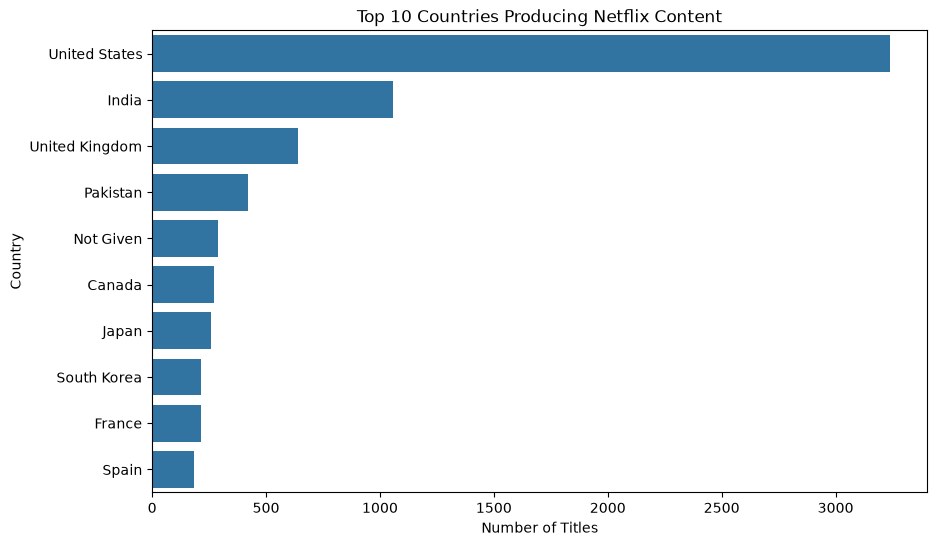

In [21]:
countries = data['country'].str.split(', ').explode()

top_countries = countries.value_counts().head(10)

print("Top 10 Countries:")
print(top_countries)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')

plt.show()

In [22]:
print("Number of unique genre combinations:")
print(data['listed_in'].nunique())

print("\nTop 15 Genre Combinations:")
print(data['listed_in'].value_counts().head(15))

Number of unique genre combinations:
513

Top 15 Genre Combinations:
listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            219
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Comedies, International Movies                      176
Comedies, International Movies, Romantic Movies     152
Dramas                                              137
Dramas, International Movies, Thrillers             134
Action & Adventure, Dramas, International Movies    132
Name: count, dtype: int64


In [23]:
# Split genre combinations into individual genres
genre_list = data['listed_in'].str.split(', ')

# Get all unique genres
unique_genres = sorted(set(
    genre
    for genres in genre_list
    for genre in genres
))

print("Total Individual Genres:", len(unique_genres))

print("\nIndividual Genres:")
print(unique_genres)

Total Individual Genres: 42

Individual Genres:
['Action & Adventure', 'Anime Features', 'Anime Series', 'British TV Shows', 'Children & Family Movies', 'Classic & Cult TV', 'Classic Movies', 'Comedies', 'Crime TV Shows', 'Cult Movies', 'Documentaries', 'Docuseries', 'Dramas', 'Faith & Spirituality', 'Horror Movies', 'Independent Movies', 'International Movies', 'International TV Shows', "Kids' TV", 'Korean TV Shows', 'LGBTQ Movies', 'Movies', 'Music & Musicals', 'Reality TV', 'Romantic Movies', 'Romantic TV Shows', 'Sci-Fi & Fantasy', 'Science & Nature TV', 'Spanish-Language TV Shows', 'Sports Movies', 'Stand-Up Comedy', 'Stand-Up Comedy & Talk Shows', 'TV Action & Adventure', 'TV Comedies', 'TV Dramas', 'TV Horror', 'TV Mysteries', 'TV Sci-Fi & Fantasy', 'TV Shows', 'TV Thrillers', 'Teen TV Shows', 'Thrillers']


In [24]:
# Create a binary column for each genre
for genre in unique_genres:
    data[genre] = data['listed_in'].apply(
        lambda x: int(genre in x.split(', '))
    )

# Display the encoded genre columns
print(data[unique_genres].head())

print("\nEncoded Dataset Shape:", data.shape)

   Action & Adventure  Anime Features  Anime Series  British TV Shows  \
0                   0               0             0                 0   
1                   0               0             0                 0   
2                   0               0             0                 0   
3                   0               0             0                 0   
4                   0               0             0                 0   

   Children & Family Movies  Classic & Cult TV  Classic Movies  Comedies  \
0                         0                  0               0         0   
1                         0                  0               0         0   
2                         0                  0               0         0   
3                         1                  0               0         1   
4                         0                  0               0         0   

   Crime TV Shows  Cult Movies  ...  TV Action & Adventure  TV Comedies  \
0               0            

In [25]:
# Count the number of genres assigned to each title
data['genre_count'] = data[unique_genres].sum(axis=1)

print("Genre Count Distribution:")
print(data['genre_count'].value_counts().sort_index())

print("\nAverage Genres per Title:")
print(data['genre_count'].mean())

print("\nSample Verification:")
print(data[['listed_in', 'genre_count']].head(10))

Genre Count Distribution:
genre_count
1    2012
2    3052
3    3726
Name: count, dtype: int64

Average Genres per Title:
2.194994311717861

Sample Verification:
                                           listed_in  genre_count
0                                      Documentaries            1
1  Crime TV Shows, International TV Shows, TV Act...            3
2                 TV Dramas, TV Horror, TV Mysteries            3
3                 Children & Family Movies, Comedies            2
4   Dramas, Independent Movies, International Movies            3
5                       British TV Shows, Reality TV            2
6                                   Comedies, Dramas            2
7  Children & Family Movies, Comedies, Music & Mu...            3
8                       Dramas, International Movies            2
9         Children & Family Movies, Music & Musicals            2


In [26]:
# Replace missing country information
data['country'] = data['country'].replace('Not Given', 'Unknown')

# Split country values
country_list = data['country'].str.split(', ')

# Extract unique countries
unique_countries = sorted(set(
    country
    for countries in country_list
    for country in countries
))

print("Total Unique Countries:", len(unique_countries))
print("\nCountries:")
print(unique_countries)

Total Unique Countries: 86

Countries:
['Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belarus', 'Belgium', 'Brazil', 'Bulgaria', 'Cambodia', 'Cameroon', 'Canada', 'Chile', 'China', 'Colombia', 'Croatia', 'Cyprus', 'Czech Republic', 'Denmark', 'Egypt', 'Finland', 'France', 'Georgia', 'Germany', 'Ghana', 'Greece', 'Guatemala', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Ireland', 'Israel', 'Italy', 'Jamaica', 'Japan', 'Jordan', 'Kenya', 'Kuwait', 'Lebanon', 'Luxembourg', 'Malaysia', 'Mauritius', 'Mexico', 'Mozambique', 'Namibia', 'Netherlands', 'New Zealand', 'Nigeria', 'Norway', 'Pakistan', 'Paraguay', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Puerto Rico', 'Romania', 'Russia', 'Saudi Arabia', 'Senegal', 'Serbia', 'Singapore', 'Slovenia', 'Somalia', 'South Africa', 'South Korea', 'Soviet Union', 'Spain', 'Sweden', 'Switzerland', 'Syria', 'Taiwan', 'Thailand', 'Turkey', 'Ukraine', 'United Arab Emirates', 'United Kingdom', 'United States', 'Unknown', 'Urugu

In [27]:
# Create binary columns for each country
for country in unique_countries:
    data[country] = data['country'].apply(
        lambda x: int(country in x.split(', '))
    )

# Display encoded country columns
print(data[unique_countries].head())

print("\nUpdated Dataset Shape:", data.shape)

C:\Users\dhars\AppData\Local\Temp\ipykernel_31580\3756365039.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[country] = data['country'].apply(
C:\Users\dhars\AppData\Local\Temp\ipykernel_31580\3756365039.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data[country] = data['country'].apply(
C:\Users\dhars\AppData\Local\Temp\ipykernel_31580\3756365039.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining

   Argentina  Australia  Austria  Bangladesh  Belarus  Belgium  Brazil  \
0          0          0        0           0        0        0       0   
1          0          0        0           0        0        0       0   
2          0          0        0           0        0        0       0   
3          0          0        0           0        0        0       1   
4          0          0        0           0        0        0       0   

   Bulgaria  Cambodia  Cameroon  ...  Ukraine  United Arab Emirates  \
0         0         0         0  ...        0                     0   
1         0         0         0  ...        0                     0   
2         0         0         0  ...        0                     0   
3         0         0         0  ...        0                     0   
4         0         0         0  ...        0                     0   

   United Kingdom  United States  Unknown  Uruguay  Venezuela  Vietnam  \
0               0              1        0        0    

In [28]:
print("Country columns:", len(unique_countries))

print("\nTotal country assignments per title:")
print(data[unique_countries].sum(axis=1).value_counts().sort_index())

print("\nUpdated Dataset Shape:", data.shape)

Country columns: 86

Total country assignments per title:
1    8790
Name: count, dtype: int64

Updated Dataset Shape: (8790, 137)


In [29]:
# One-Hot Encoding
type_encoded = pd.get_dummies(data['type'], prefix='type', dtype=int)

rating_encoded = pd.get_dummies(data['rating'], prefix='rating', dtype=int)

# Add encoded columns to dataset
data = pd.concat([data, type_encoded, rating_encoded], axis=1)

print("Encoded Type Columns:")
print(type_encoded.head())

print("\nEncoded Rating Columns:")
print(rating_encoded.head())

print("\nUpdated Dataset Shape:", data.shape)

Encoded Type Columns:
   type_Movie  type_TV Show
0           1             0
1           0             1
2           0             1
3           1             0
4           1             0

Encoded Rating Columns:
   rating_G  rating_NC-17  rating_NR  rating_PG  rating_PG-13  rating_R  \
0         0             0          0          0             1         0   
1         0             0          0          0             0         0   
2         0             0          0          0             0         0   
3         0             0          0          0             0         0   
4         0             0          0          0             0         0   

   rating_TV-14  rating_TV-G  rating_TV-MA  rating_TV-PG  rating_TV-Y  \
0             0            0             0             0            0   
1             0            0             1             0            0   
2             0            0             1             0            0   
3             0            0             0

In [31]:
columns_to_drop = [
    'show_id',
    'title',
    'director',
    'date_added',
    'type',
    'country',
    'rating',
    'duration',
    'listed_in',
    'genre_count'
]

# Remove only columns that currently exist
data.drop(
    columns=[col for col in columns_to_drop if col in data.columns],
    inplace=True
)

print("Unnecessary columns removed successfully!")

print("\nFinal Feature Dataset Shape:", data.shape)
print("\nRemaining Columns:")
print(data.columns.tolist())

Unnecessary columns removed successfully!

Final Feature Dataset Shape: (8790, 147)

Remaining Columns:
['release_year', 'movie_duration', 'num_seasons', 'Action & Adventure', 'Anime Features', 'Anime Series', 'British TV Shows', 'Children & Family Movies', 'Classic & Cult TV', 'Classic Movies', 'Comedies', 'Crime TV Shows', 'Cult Movies', 'Documentaries', 'Docuseries', 'Dramas', 'Faith & Spirituality', 'Horror Movies', 'Independent Movies', 'International Movies', 'International TV Shows', "Kids' TV", 'Korean TV Shows', 'LGBTQ Movies', 'Movies', 'Music & Musicals', 'Reality TV', 'Romantic Movies', 'Romantic TV Shows', 'Sci-Fi & Fantasy', 'Science & Nature TV', 'Spanish-Language TV Shows', 'Sports Movies', 'Stand-Up Comedy', 'Stand-Up Comedy & Talk Shows', 'TV Action & Adventure', 'TV Comedies', 'TV Dramas', 'TV Horror', 'TV Mysteries', 'TV Sci-Fi & Fantasy', 'TV Shows', 'TV Thrillers', 'Teen TV Shows', 'Thrillers', 'Argentina', 'Australia', 'Austria', 'Bangladesh', 'Belarus', 'Belgium

C:\Users\dhars\AppData\Local\Temp\ipykernel_31580\1122318921.py:15: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  data.drop(


In [32]:
from sklearn.preprocessing import StandardScaler

# Initialize StandardScaler
scaler = StandardScaler()

# Scale all features
scaled_data = scaler.fit_transform(data)

# Convert scaled data back to DataFrame
scaled_df = pd.DataFrame(
    scaled_data,
    columns=data.columns,
    index=data.index
)

print("Scaled Dataset Shape:", scaled_df.shape)

print("\nScaled Feature Statistics:")
print(scaled_df.describe().round(2))

Scaled Dataset Shape: (8790, 147)

Scaled Feature Statistics:
       release_year  movie_duration  num_seasons  Action & Adventure  \
count       8790.00         8790.00      8790.00             8790.00   
mean           0.00            0.00        -0.00                0.00   
std            1.00            1.00         1.00                1.00   
min          -10.11           -1.35        -0.45               -0.33   
25%           -0.13           -1.35        -0.45               -0.33   
50%            0.32            0.37        -0.45               -0.33   
75%            0.55            0.71         0.40               -0.33   
max            0.77            4.71        14.04                3.04   

       Anime Features  Anime Series  British TV Shows  \
count         8790.00       8790.00           8790.00   
mean            -0.00          0.00             -0.00   
std              1.00          1.00              1.00   
min             -0.09         -0.14             -0.17   
25% 

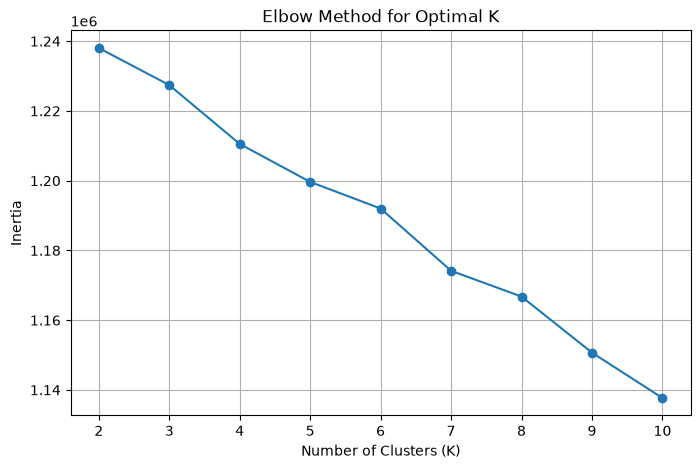

In [ ]:
from sklearn.cluster import KMeans

inertia = []

K = range(2, 11)

for k in K:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(scaled_df)

    inertia.append(kmeans.inertia_)

# Plot Elbow Curve
plt.figure(figsize=(8, 5))

plt.plot(K, inertia, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(K)
plt.grid(True)

plt.show()

In [34]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in [4, 5, 6, 7]:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(scaled_df)

    score = silhouette_score(
        scaled_df,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 4, Silhouette Score = 0.0065
K = 5, Silhouette Score = 0.0335
K = 6, Silhouette Score = 0.0534
K = 7, Silhouette Score = 0.0246


In [35]:
# Initialize K-Means
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Train the model and assign clusters
data['Cluster'] = kmeans.fit_predict(scaled_df)

print("K-Means Model Trained Successfully!")

print("\nCluster Distribution:")
print(data['Cluster'].value_counts().sort_index())

K-Means Model Trained Successfully!

Cluster Distribution:
Cluster
0     244
1    1752
2     123
3    5773
4     734
5     164
Name: count, dtype: int64


C:\Users\dhars\AppData\Local\Temp\ipykernel_31580\2115060678.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  data['Cluster'] = kmeans.fit_predict(scaled_df)


In [36]:
# Connect original dataset with predicted cluster labels
cluster_analysis = df.copy()

cluster_analysis['Cluster'] = data['Cluster']

print("Cluster Analysis Dataset:")
print(cluster_analysis.head())

print("\nCluster-wise Content Distribution:")
print(cluster_analysis['Cluster'].value_counts().sort_index())

Cluster Analysis Dataset:
  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  Cluster  
0                                      Documentaries        3  
1  Crime TV Shows, International T

Content Type Distribution Across Clusters:
type     Movie  TV Show
Cluster                
0          244        0
1            0     1752
2          109       14
3         5773        0
4            0      734
5            0      164


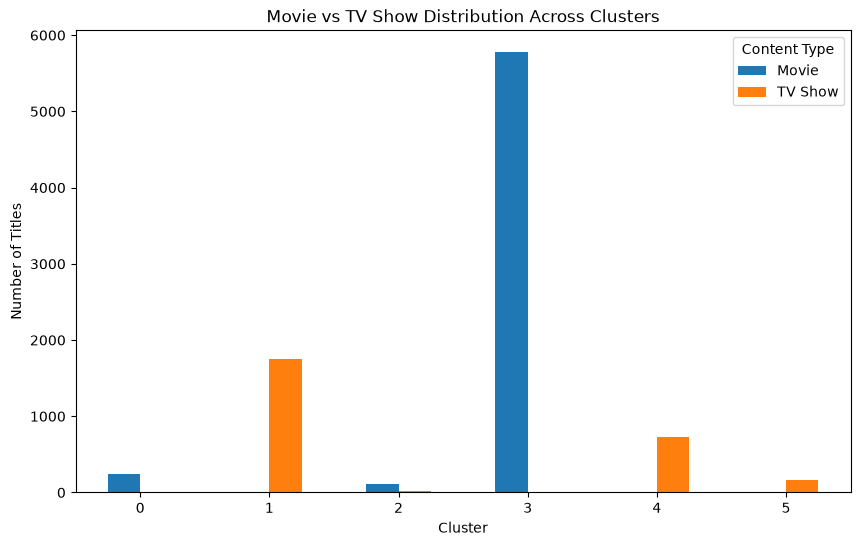

In [37]:
cluster_type = pd.crosstab(
    cluster_analysis['Cluster'],
    cluster_analysis['type']
)

print("Content Type Distribution Across Clusters:")
print(cluster_type)

# Visualize the distribution
cluster_type.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Movie vs TV Show Distribution Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Content Type')
plt.show()

In [38]:
# Calculate genre distribution for each cluster
cluster_genres = cluster_analysis.groupby('Cluster')['listed_in'].apply(
    lambda x: x.str.split(', ').explode().value_counts().head(5)
)

print("Top 5 Genres in Each Cluster:")
print(cluster_genres)

Top 5 Genres in Each Cluster:
Cluster                        
0        Sci-Fi & Fantasy           243
         Action & Adventure         125
         International Movies        51
         Dramas                      43
         Thrillers                   37
1        International TV Shows     917
         TV Dramas                  701
         TV Comedies                502
         Kids' TV                   392
         Crime TV Shows             312
2        International Movies       106
         Comedies                    63
         Dramas                      47
         Action & Adventure          15
         International TV Shows      14
3        International Movies      2595
         Dramas                    2336
         Comedies                  1578
         Documentaries              868
         Independent Movies         732
4        Docuseries                 394
         International TV Shows     277
         British TV Shows           251
         Reality T

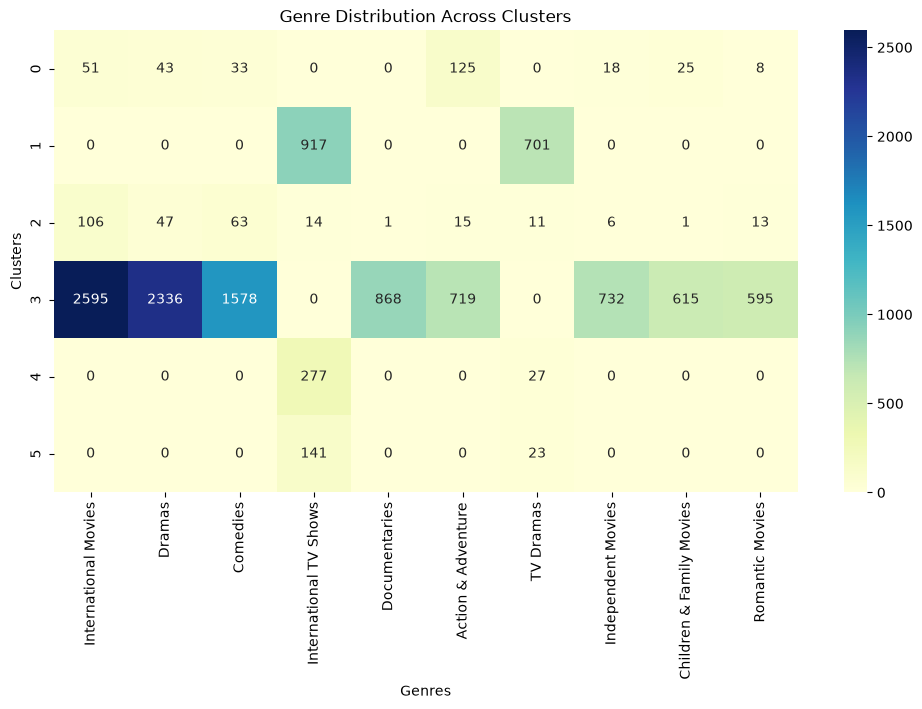

In [39]:
# Extract individual genres
genre_data = cluster_analysis.copy()

genre_data['listed_in'] = genre_data['listed_in'].str.split(', ')

# Expand genres into separate rows
genre_data = genre_data.explode('listed_in')

# Create cluster vs genre table
genre_heatmap = pd.crosstab(
    genre_data['Cluster'],
    genre_data['listed_in']
)

# Select 10 most common genres
top_10 = genre_heatmap.sum().nlargest(10).index

# Plot heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    genre_heatmap[top_10],
    annot=True,
    fmt='d',
    cmap='YlGnBu'
)

plt.title('Genre Distribution Across Clusters')
plt.xlabel('Genres')
plt.ylabel('Clusters')
plt.show()

Cluster-wise Content Type Percentage:
type      Movie  TV Show
Cluster                 
0        100.00     0.00
1          0.00   100.00
2         88.62    11.38
3        100.00     0.00
4          0.00   100.00
5          0.00   100.00


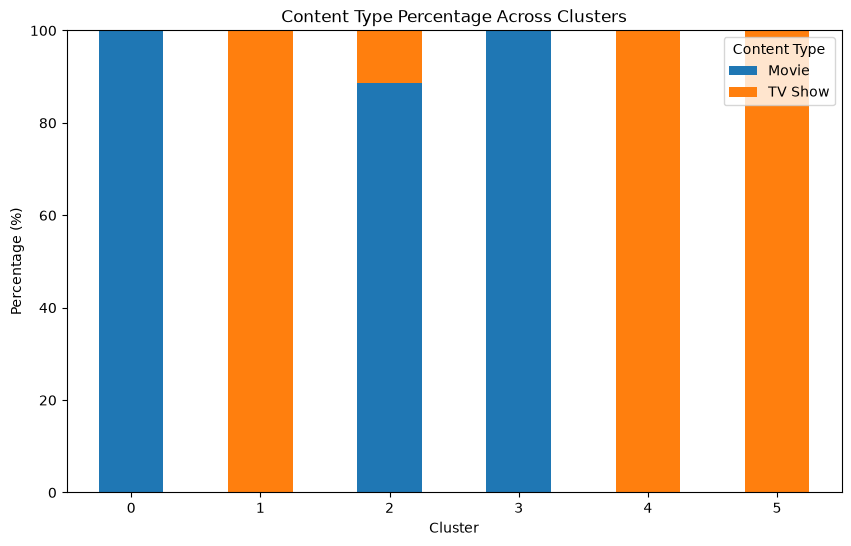

In [40]:
# Count content types in each cluster
cluster_type = pd.crosstab(
    cluster_analysis['Cluster'],
    cluster_analysis['type']
)

# Convert counts into percentages
cluster_percentage = cluster_type.div(
    cluster_type.sum(axis=1),
    axis=0
) * 100

print("Cluster-wise Content Type Percentage:")
print(cluster_percentage.round(2))

# Visualize
cluster_percentage.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Content Type Percentage Across Clusters')
plt.xlabel('Cluster')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='Content Type')

plt.show()

In [41]:
# Calculate average numerical feature values for each cluster
cluster_features = scaled_df.copy()

cluster_features['Cluster'] = data['Cluster']

cluster_profile = cluster_features.groupby('Cluster').mean()

print("Cluster Feature Profiles:")
print(cluster_profile[['release_year', 'movie_duration', 'num_seasons']].round(2))

Cluster Feature Profiles:
         release_year  movie_duration  num_seasons
Cluster                                           
0               -0.27            0.71        -0.45
1                0.24           -1.35         1.16
2               -0.60            0.50        -0.36
3               -0.10            0.58        -0.45
4                0.35           -1.35         0.86
5                0.29           -1.35         0.61


In [42]:
from sklearn.metrics import silhouette_score

final_silhouette = silhouette_score(
    scaled_df,
    data['Cluster'],
    sample_size=2000,
    random_state=42
)

print("Final Silhouette Score:", round(final_silhouette, 4))

Final Silhouette Score: 0.0534


In [43]:
from sklearn.preprocessing import StandardScaler

# Remove cluster column if present
improved_data = data.drop(columns=['Cluster'], errors='ignore').copy()

# Select continuous numerical features
numerical_features = [
    'release_year',
    'movie_duration',
    'num_seasons'
]

# Scale only numerical features
scaler_improved = StandardScaler()

improved_data[numerical_features] = scaler_improved.fit_transform(
    improved_data[numerical_features]
)

print("Improved Dataset Shape:", improved_data.shape)

print("\nNumerical Feature Statistics:")
print(improved_data[numerical_features].describe().round(2))

print("\nBinary Feature Values:")
print(improved_data.drop(columns=numerical_features).stack().unique())

Improved Dataset Shape: (8790, 147)

Numerical Feature Statistics:
       release_year  movie_duration  num_seasons
count       8790.00         8790.00      8790.00
mean           0.00            0.00        -0.00
std            1.00            1.00         1.00
min          -10.11           -1.35        -0.45
25%           -0.13           -1.35        -0.45
50%            0.32            0.37        -0.45
75%            0.55            0.71         0.40
max            0.77            4.71        14.04

Binary Feature Values:
[0 1]


In [44]:
# Train improved K-Means model
kmeans_improved = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

# Generate cluster labels
improved_labels = kmeans_improved.fit_predict(improved_data)

print("Improved K-Means Model Trained!")

print("\nImproved Cluster Distribution:")
print(pd.Series(improved_labels).value_counts().sort_index())

Improved K-Means Model Trained!

Improved Cluster Distribution:
0    2398
1    2003
2    2481
3     386
4     252
5    1270
Name: count, dtype: int64


In [45]:
improved_silhouette = silhouette_score(
    improved_data,
    improved_labels,
    sample_size=2000,
    random_state=42
)

print("Original Silhouette Score:", round(final_silhouette, 4))

print("Improved Silhouette Score:", round(improved_silhouette, 4))

Original Silhouette Score: 0.0534
Improved Silhouette Score: 0.1566


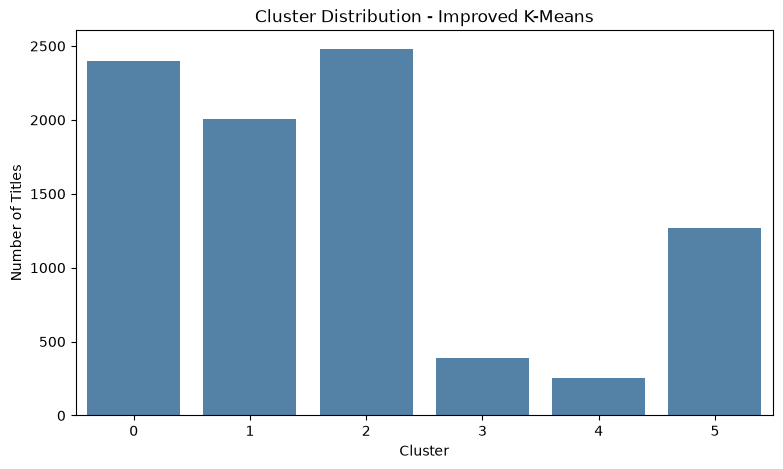

In [46]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x=improved_labels,
    color='steelblue'
)

plt.title('Cluster Distribution - Improved K-Means')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')

plt.show()

In [47]:
# Create a new analysis dataset
improved_analysis = df.copy()

improved_analysis['Cluster'] = improved_labels

print("Improved Cluster Analysis:")
print(improved_analysis.head())

print("\nCluster Distribution:")
print(improved_analysis['Cluster'].value_counts().sort_index())


Improved Cluster Analysis:
  show_id     type                             title         director  \
0      s1    Movie              Dick Johnson Is Dead  Kirsten Johnson   
1      s3  TV Show                         Ganglands  Julien Leclercq   
2      s6  TV Show                     Midnight Mass    Mike Flanagan   
3     s14    Movie  Confessions of an Invisible Girl    Bruno Garotti   
4      s8    Movie                           Sankofa     Haile Gerima   

         country date_added  release_year rating  duration  \
0  United States  9/25/2021          2020  PG-13    90 min   
1         France  9/24/2021          2021  TV-MA  1 Season   
2  United States  9/24/2021          2021  TV-MA  1 Season   
3         Brazil  9/22/2021          2021  TV-PG    91 min   
4  United States  9/24/2021          1993  TV-MA   125 min   

                                           listed_in  Cluster  
0                                      Documentaries        1  
1  Crime TV Shows, International 

type     Movie  TV Show
Cluster                
0            0     2398
1         2003        0
2         2481        0
3          372       14
4            0      252
5         1270        0


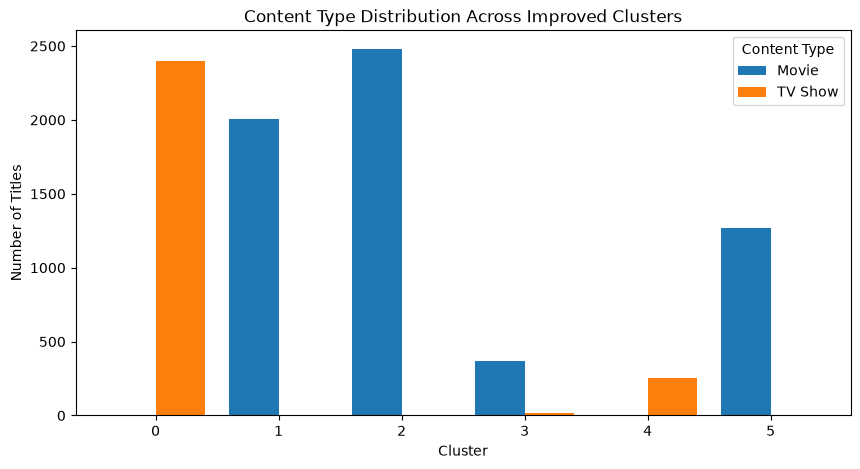

In [48]:
type_distribution = pd.crosstab(
    improved_analysis['Cluster'],
    improved_analysis['type']
)

print(type_distribution)

type_distribution.plot(
    kind='bar',
    figsize=(10, 5),
    width=0.8
)

plt.title('Content Type Distribution Across Improved Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Content Type')
plt.show()

In [49]:
cluster_genres_improved = improved_analysis.groupby('Cluster')['listed_in'].apply(
    lambda x: x.str.split(', ').explode().value_counts().head(5)
)

print(cluster_genres_improved)

Cluster                          
0        International TV Shows      1293
         TV Dramas                    671
         TV Comedies                  481
         Crime TV Shows               431
         Kids' TV                     389
1        Documentaries                707
         Children & Family Movies     439
         Stand-Up Comedy              319
         Comedies                     303
         Dramas                       228
2        International Movies        2379
         Dramas                      1472
         Comedies                     825
         Romantic Movies              364
         Action & Adventure           360
3        Dramas                       171
         International Movies         144
         Classic Movies               115
         Action & Adventure           114
         Comedies                     104
4        TV Comedies                   91
         TV Dramas                     90
         Kids' TV                      56


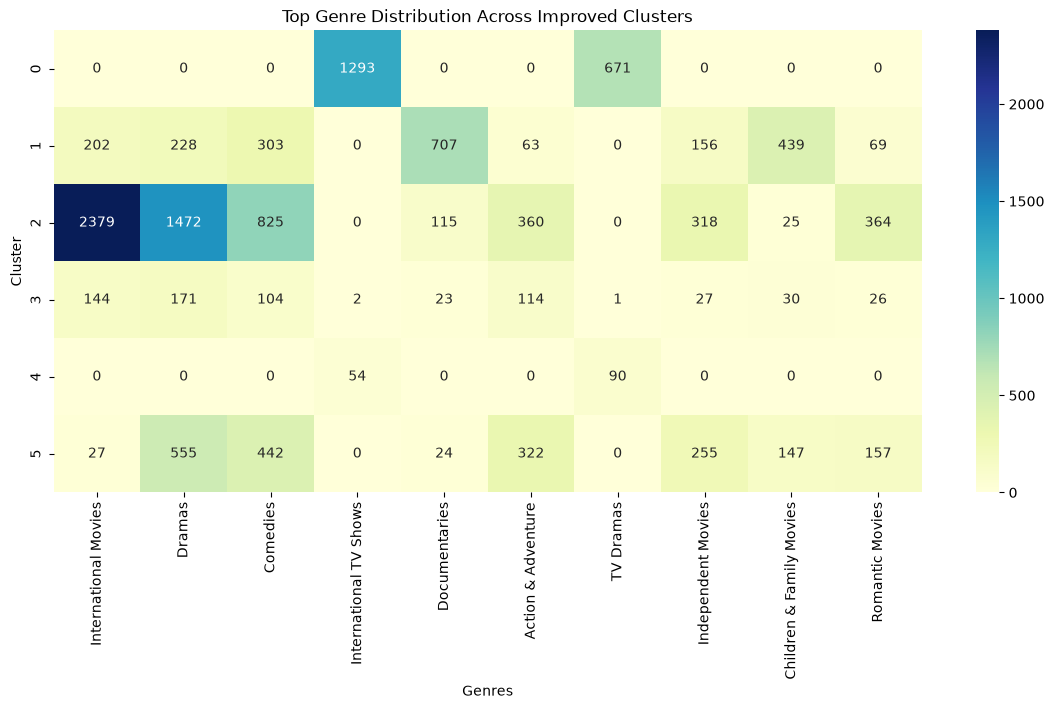

In [50]:
top_genres = (
    improved_analysis['listed_in']
    .str.split(', ')
    .explode()
    .value_counts()
    .head(10)
    .index
)

genre_cluster_data = pd.DataFrame(index=sorted(improved_analysis['Cluster'].unique()))

for genre in top_genres:
    genre_cluster_data[genre] = improved_analysis.groupby('Cluster')['listed_in'].apply(
        lambda x: x.str.split(', ').apply(lambda genres: genre in genres).sum()
    )

plt.figure(figsize=(14, 6))
sns.heatmap(genre_cluster_data, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Top Genre Distribution Across Improved Clusters')
plt.xlabel('Genres')
plt.ylabel('Cluster')
plt.show()

In [51]:
numerical_profile = improved_analysis.groupby('Cluster').agg(
    Average_Release_Year=('release_year', 'mean'),
    Average_Movie_Duration=('duration', lambda x: x[x.str.contains('min', na=False)]
                            .str.extract(r'(\d+)')[0].astype(float).mean()),
    Average_TV_Seasons=('duration', lambda x: x[x.str.contains('Season', na=False)]
                        .str.extract(r'(\d+)')[0].astype(float).mean()),
    Total_Titles=('title', 'count')
)

print(numerical_profile.round(2))

         Average_Release_Year  Average_Movie_Duration  Average_TV_Seasons  \
Cluster                                                                     
0                     2017.03                     NaN                1.34   
1                     2017.24                   76.50                 NaN   
2                     2015.39                  112.93                 NaN   
3                     1982.19                  115.31                1.43   
4                     2015.25                     NaN                5.68   
5                     2011.14                  105.33                 NaN   

         Total_Titles  
Cluster                
0                2398  
1                2003  
2                2481  
3                 386  
4                 252  
5                1270  


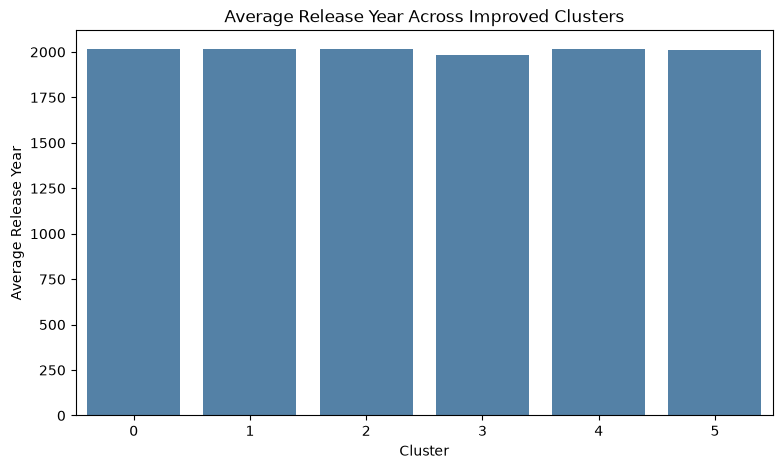

In [52]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=numerical_profile.index,
    y=numerical_profile['Average_Release_Year'],
    color='steelblue'
)

plt.title('Average Release Year Across Improved Clusters')
plt.xlabel('Cluster')
plt.ylabel('Average Release Year')
plt.xticks(rotation=0)
plt.show()

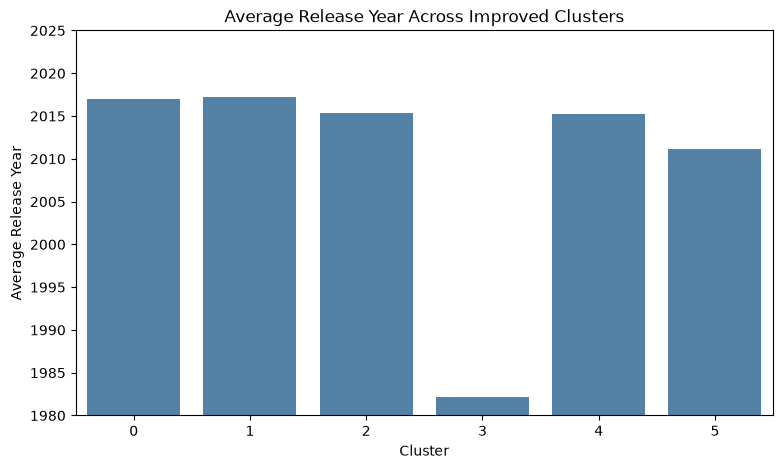

In [53]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=numerical_profile.index,
    y=numerical_profile['Average_Release_Year'].values,
    color='steelblue'
)

plt.title('Average Release Year Across Improved Clusters')
plt.xlabel('Cluster')
plt.ylabel('Average Release Year')
plt.ylim(1980, 2025)
plt.xticks(rotation=0)
plt.show()

In [54]:
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(improved_data)

    score = silhouette_score(
        improved_data,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_scores.append(score)
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3004
K = 3, Silhouette Score = 0.2876
K = 4, Silhouette Score = 0.1587
K = 5, Silhouette Score = 0.1729
K = 6, Silhouette Score = 0.1566
K = 7, Silhouette Score = 0.1555
K = 8, Silhouette Score = 0.1220


In [55]:
kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

final_labels = kmeans_final.fit_predict(improved_data)

final_analysis = df.copy()
final_analysis['Cluster'] = final_labels

print("Cluster Distribution:")
print(final_analysis['Cluster'].value_counts().sort_index())

Cluster Distribution:
Cluster
0    5512
1     631
2    2647
Name: count, dtype: int64


type     Movie  TV Show
Cluster                
0         5512        0
1          614       17
2            0     2647


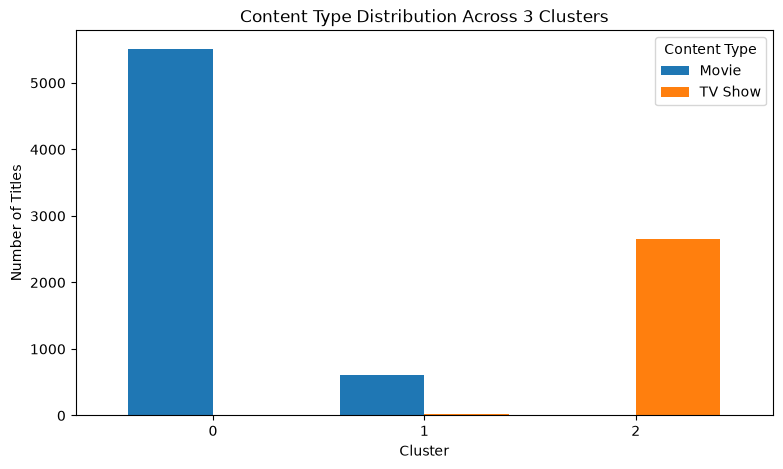

In [56]:
type_distribution_final = pd.crosstab(
    final_analysis['Cluster'],
    final_analysis['type']
)

print(type_distribution_final)

type_distribution_final.plot(
    kind='bar',
    figsize=(9, 5),
    width=0.8
)

plt.title('Content Type Distribution Across 3 Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Content Type')
plt.show()

In [57]:
cluster_genres_final = final_analysis.groupby('Cluster')['listed_in'].apply(
    lambda x: x.str.split(', ').explode().value_counts().head(7)
)

print(cluster_genres_final)

Cluster                          
0        International Movies        2553
         Dramas                      2158
         Comedies                    1465
         Documentaries                839
         Independent Movies           713
         Action & Adventure           670
         Children & Family Movies     591
1        Dramas                       268
         Comedies                     209
         International Movies         199
         Action & Adventure           189
         Classic Movies               115
         Romantic Movies               63
         Cult Movies                   50
2        International TV Shows      1347
         TV Dramas                    761
         TV Comedies                  571
         Crime TV Shows               469
         Kids' TV                     444
         Docuseries                   392
         Romantic TV Shows            370
Name: listed_in, dtype: int64


In [58]:
comparison = pd.DataFrame({
    'Model': ['K-Means (3 Clusters)', 'K-Means (6 Clusters)'],
    'Number of Clusters': [3, 6],
    'Silhouette Score': [
        silhouette_score(improved_data, final_labels,
                         sample_size=2000, random_state=42),
        silhouette_score(improved_data, improved_labels,
                         sample_size=2000, random_state=42)
    ]
})

print(comparison.round(4))

                  Model  Number of Clusters  Silhouette Score
0  K-Means (3 Clusters)                   3            0.2876
1  K-Means (6 Clusters)                   6            0.1566


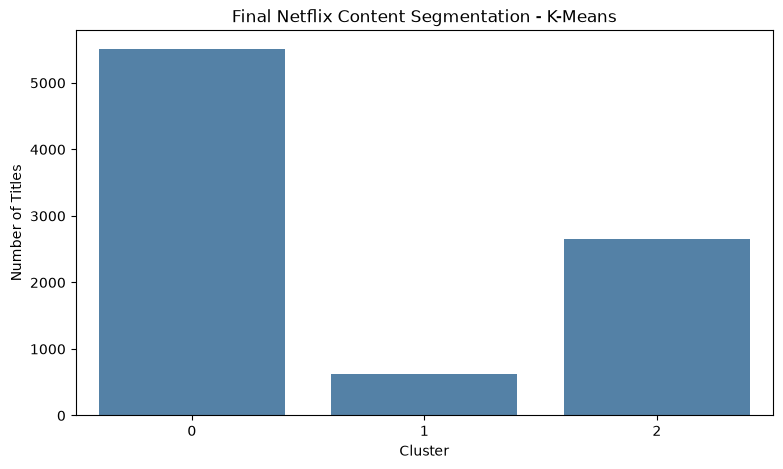

In [59]:
plt.figure(figsize=(9, 5))

sns.countplot(
    x=final_labels,
    color='steelblue'
)

plt.title('Final Netflix Content Segmentation - K-Means')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.show()

In [60]:
import joblib

joblib.dump(kmeans_final, 'kmeans_model.pkl')
joblib.dump(scaler_improved, 'scaler.pkl')
joblib.dump(numerical_features, 'numerical_features.pkl')
joblib.dump(improved_data.columns.tolist(), 'feature_columns.pkl')

print("Final K-Means model and preprocessing objects saved successfully!")

Final K-Means model and preprocessing objects saved successfully!


In [61]:
final_analysis['Cluster'] = final_labels

final_analysis.to_csv('Netflix_Clustered_Data.csv', index=False)

print("Clustered dataset exported successfully!")
print("Total titles:", len(final_analysis))
print("\nCluster counts:")
print(final_analysis['Cluster'].value_counts().sort_index())

Clustered dataset exported successfully!
Total titles: 8790

Cluster counts:
Cluster
0    5512
1     631
2    2647
Name: count, dtype: int64


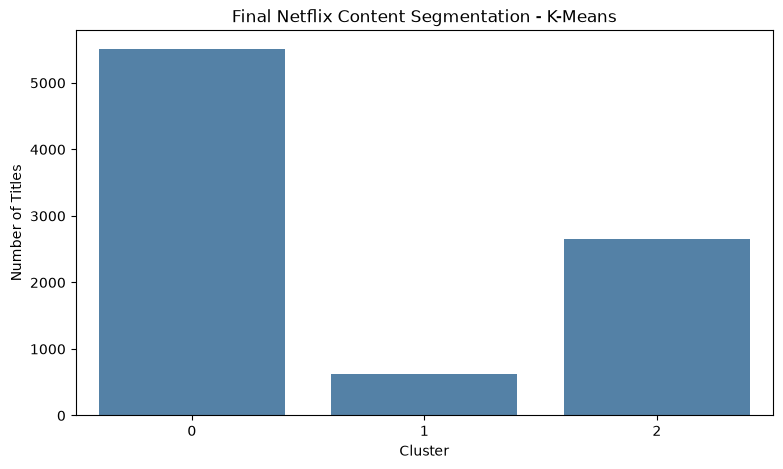

Final cluster graph saved in the images folder!


In [62]:
import os

os.makedirs('images', exist_ok=True)

plt.figure(figsize=(9, 5))

sns.countplot(x=final_labels, color='steelblue')

plt.title('Final Netflix Content Segmentation - K-Means')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')

plt.savefig('images/final_cluster_distribution.png',
            dpi=300, bbox_inches='tight')

plt.show()

print("Final cluster graph saved in the images folder!")

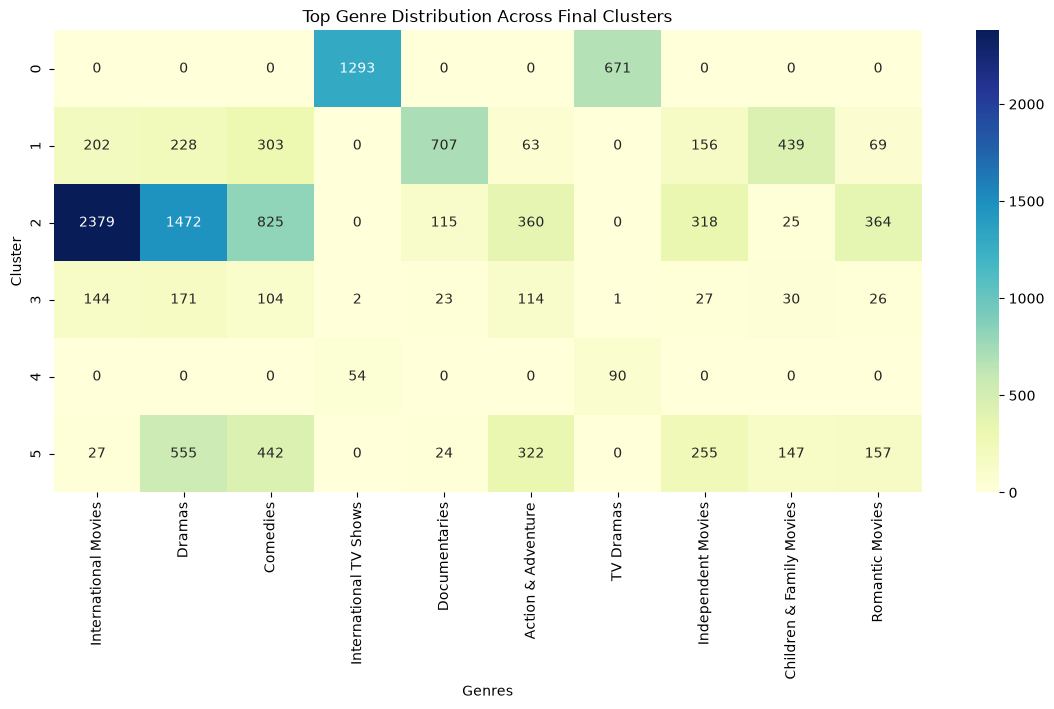

Genre heatmap saved successfully!


In [63]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    genre_cluster_data,
    annot=True,
    fmt='.0f',
    cmap='YlGnBu'
)

plt.title('Top Genre Distribution Across Final Clusters')
plt.xlabel('Genres')
plt.ylabel('Cluster')

plt.savefig(
    'images/final_genre_heatmap.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Genre heatmap saved successfully!")

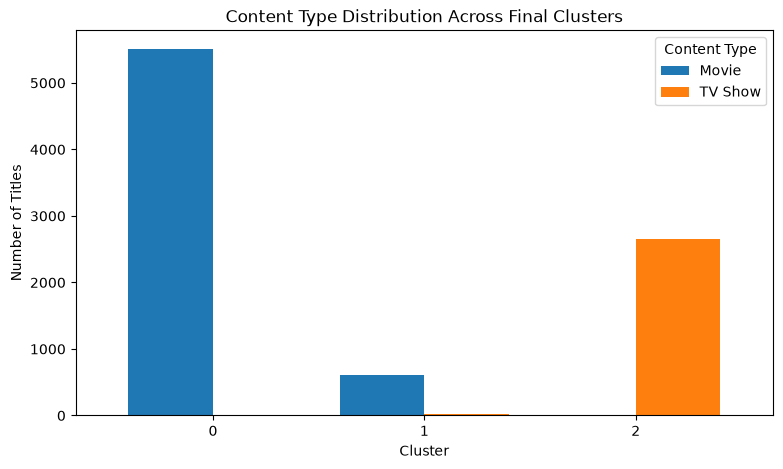

Content type distribution graph saved successfully!


In [64]:
plt.figure(figsize=(9, 5))

type_distribution_final.plot(
    kind='bar',
    width=0.8,
    ax=plt.gca()
)

plt.title('Content Type Distribution Across Final Clusters')
plt.xlabel('Cluster')
plt.ylabel('Number of Titles')
plt.xticks(rotation=0)
plt.legend(title='Content Type')

plt.savefig(
    'images/final_content_type_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

print("Content type distribution graph saved successfully!")

In [65]:
print("Saved project files:\n")

for root, dirs, files in os.walk('.'):
    dirs[:] = [d for d in dirs if d not in ['.ipynb_checkpoints', '__pycache__']]

    for file in files:
        if file.endswith(('.pkl', '.csv', '.png')):
            print(os.path.join(root, file))

Saved project files:

.\Dataset.csv
.\feature_columns.pkl
.\kmeans_model.pkl
.\Netflix_Clustered_Data.csv
.\numerical_features.pkl
.\scaler.pkl
.\images\final_cluster_distribution.png
.\images\final_content_type_distribution.png
.\images\final_genre_heatmap.png
